# 07. Quantile forecasts

**Where we are:** notebook 06 built a LightGBM point forecast. With forecast weather it is about
190 MW behind NESO on spring 2024.

**Why a probabilistic forecast:** a single number hides how sure the forecast is. A grid operator
or trader holding reserve needs to know the range demand could fall in, and how likely the
extremes are. NESO's published day-ahead forecast is a single number, so a well-calibrated range
is something it does not offer.

**What this notebook does:**

1. Trains LightGBM to predict quantiles of demand (5% to 95%) instead of a single value.
2. Scores them with pinball loss and checks how often the intervals contain what happened.
3. Compares with a simple reference: the point forecast plus the spread of its recent errors.

**Background reading**
- [Quantile regression](https://en.wikipedia.org/wiki/Quantile_regression)
- [Forecasting: Principles and Practice, section 5.9, evaluating distributional forecast accuracy](https://otexts.com/fpp3/distaccuracy.html)
- [Gneiting and Raftery, Strictly proper scoring rules, prediction, and estimation](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf)


## Step 1. Set up and load

The feature table and the model settings come from notebook 06: the target is demand minus the
latest 24 hours of live demand, with 17 features (no lockdown flag), trained on all data from 2019.


In [1]:
from pathlib import Path

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

features_actual = pd.read_parquet(PROCESSED / "features_actual.parquet")
features_forecast = pd.read_parquet(PROCESSED / "features_forecast.parquet")
point = pd.read_parquet(PROCESSED / "validation_forecasts.parquet")
point = point[point["model"] == "LightGBM (actual weather)"]

COLUMNS = ["slot", "weekday", "month", "day_of_year", "holiday", "christmas", "lag7", "lag14",
           "similar_day", "level24", "level_ratio", "solar_capacity", "temperature_2m",
           "temp_day_mean", "wind_speed_10m", "shortwave_radiation", "radiation_x_capacity"]
PARAMS = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=4, verbose=-1, random_state=0)
QUANTILES = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]
FOLDS = pd.DataFrame([{"fold": f"{s:%Y-%m}", "train_until": s - pd.Timedelta(days=2),
                        "start": s, "end": s + pd.offsets.MonthEnd(0)}
                       for s in pd.date_range("2022-06-01", "2024-05-01", freq="MS")])


## Step 2. Quantile regression with LightGBM

**What:** train one model per quantile. The model for the 90% quantile is trained so that about
90% of outcomes fall below its forecast.

**How:** LightGBM's `quantile` objective minimises the pinball loss for a chosen level `q`.
Under-forecasting by 1 MW costs `q`, over-forecasting by 1 MW costs `1 − q`. At `q = 0.9`, being
too low costs nine times more than being too high, so the model learns to aim high, at the point
with 90% of outcomes below it. At `q = 0.5` it gives the median.

**Why separate models:** it is the simplest way to get quantiles from boosted trees. The
downside is that nothing forces the 90% forecast to sit above the 75% one; Step 3 checks this.


In [2]:
def run_quantile_folds(features, train_table=None, folds=FOLDS):
    train_table = features if train_table is None else train_table
    date, train_date = pd.to_datetime(features["Date"]), pd.to_datetime(train_table["Date"])
    parts = []
    for fold in folds.itertuples():
        train = train_table[(train_date <= fold.train_until) & train_table["ND"].notna()]
        test = features[date.between(fold.start, fold.end) & features["Demand_Outturn"].notna()]
        out = test[["start_utc", "Date", "slot", "Demand_Forecast", "Demand_Outturn"]].assign(fold=fold.fold)
        for q in QUANTILES:
            model = lgb.LGBMRegressor(objective="quantile", alpha=q, **PARAMS)
            model.fit(train[COLUMNS], train["ND"] - train["level24"])
            out[f"q{q}"] = model.predict(test[COLUMNS]) + test["level24"]
        parts.append(out)
    return pd.concat(parts, ignore_index=True)


QCOLS = [f"q{q}" for q in QUANTILES]
quantile = run_quantile_folds(features_actual)
print(f"{len(quantile):,} half-hours, {len(QUANTILES)} quantiles")
quantile[["Date", "Demand_Outturn"] + QCOLS].head(3).round(0)


35,038 half-hours, 7 quantiles


,Date,Demand_Outturn,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95
0,2022-06-01,21466.0,20822.0,20879.0,21367.0,21489.0,21561.0,21902.0,22178.0
1,2022-06-01,20977.0,20317.0,20414.0,20781.0,21017.0,20971.0,21147.0,21483.0
2,2022-06-01,20482.0,20141.0,20051.0,20317.0,20626.0,20582.0,20855.0,21182.0


## Step 3. Do the quantiles cross?

**What:** count rows where a higher quantile is forecast below a lower one, then fix them by
sorting each row's quantiles.

**Why sorting is a fair fix:** the forecasts are meant to be ordered; sorting keeps the set of
values and only puts them in a valid order. It can only lower the pinball loss (Chernozhukov et
al., 2010, [Quantile and probability curves without crossing](https://arxiv.org/abs/0704.3649)).


In [3]:
values = quantile[QCOLS].to_numpy()
crossing = (np.diff(values, axis=1) < 0).any(axis=1)
print(f"rows with at least one crossing: {crossing.mean():.2%}")
quantile[QCOLS] = np.sort(values, axis=1)


rows with at least one crossing: 71.16%


**Found:** 71% of half-hours have at least one pair of quantiles out of order. That is a lot, and
it comes from fitting seven separate models whose trees split differently. After sorting, every
row is ordered. The high crossing rate is a first sign that the separate quantile models are noisy.


## Step 4. Scoring the quantiles

**Pinball loss:** for each quantile, the average of `q × (y − f)` when the outcome `y` is above the
forecast `f`, and `(1 − q) × (f − y)` when below. Averaged over all quantiles it rewards forecasts
that are both sharp and right. It is a *proper* score: a forecaster cannot improve it by reporting
anything other than what they believe. Lower is better, and it is in MW like MAE (at `q = 0.5`
it equals half the MAE).

**Coverage:** a 90% interval (5% to 95% quantiles) should contain the outcome 90% of the time. If
it does so less often, the forecast is overconfident; more often, it is too cautious.

**Width:** narrower intervals are more useful, but only if coverage holds.


In [4]:
def pinball(y, f, q):
    diff = y - f
    return np.mean(np.maximum(q * diff, (q - 1) * diff))


def interval_table(frame):
    y = frame["Demand_Outturn"].to_numpy()
    rows = {}
    for low, high, nominal in [(0.25, 0.75, 0.5), (0.1, 0.9, 0.8), (0.05, 0.95, 0.9)]:
        inside = (y >= frame[f"q{low}"]) & (y <= frame[f"q{high}"])
        rows[f"{nominal:.0%} interval"] = {"coverage": inside.mean(),
                                           "mean width (MW)": (frame[f"q{high}"] - frame[f"q{low}"]).mean()}
    return pd.DataFrame(rows).T


def pinball_table(frame):
    y = frame["Demand_Outturn"].to_numpy()
    losses = pd.Series({q: pinball(y, frame[f"q{q}"].to_numpy(), q) for q in QUANTILES})
    return losses


losses = pinball_table(quantile)
print("pinball loss by quantile (MW):", losses.round(1).to_dict())
print(f"mean pinball loss: {losses.mean():.1f} MW")
print(f"median forecast MAE: {(quantile['q0.5'] - quantile['Demand_Outturn']).abs().mean():.1f} MW")
interval_table(quantile).round(3)


pinball loss by quantile (MW): {0.05: 142.6, 0.1: 217.9, 0.25: 334.4, 0.5: 390.5, 0.75: 330.9, 0.9: 211.2, 0.95: 134.7}
mean pinball loss: 251.7 MW
median forecast MAE: 781.1 MW


,coverage,mean width (MW)
50% interval,0.297,753.199
80% interval,0.570,1678.935
90% interval,0.739,2537.570


**Found:**

- **The intervals are far too narrow.** The 50% interval contains the outcome 30% of the time, the
  80% interval 57% and the 90% interval 74%. The models are overconfident.
- The median forecast scores MAE 781 MW, almost the same as notebook 06's point model (779 MW), so
  the centre of the distribution is fine. The problem is the spread.
- **Why too narrow, as far as I can tell:** each quantile model learns the spread of errors on its
  own training data, where the trees fit well, so the errors look smaller than they will be on new
  days. The level of demand also drifts, so the future is less like the training years than they
  are like each other. Out-of-sample errors are larger than in-sample ones, and quantile models
  trained in-sample do not know that.


## Step 5. A reference: point forecast plus recent errors

**What:** take notebook 06's point forecast and add the quantiles of its own errors over the
previous six validation months. For example, the 95% quantile is the point forecast plus the 95th
percentile of recent errors (outturn minus forecast).

**Why this reference:** it is the simplest honest way to put a range around a point forecast, and
it uses only errors that were known before each month started. If the quantile models cannot beat
it, they are not worth their cost. Because it needs six months of history, the comparison runs on
the 18 folds from December 2022.

**Why errors by time of day:** notebook 06 found errors twice as large at midday as overnight, so
one spread for the whole day would be too wide at night and too narrow at noon. The quantiles are
taken separately for each half-hour of the day.


In [5]:
point = point.merge(quantile[["start_utc", "slot"]], on="start_utc")
point["error"] = point["Demand_Outturn"] - point["forecast"]
fold_order = list(FOLDS["fold"])

parts = []
for i, fold in enumerate(fold_order[6:], start=6):
    history = point[point["fold"].isin(fold_order[i - 6:i])]
    spread = history.groupby("slot")["error"].quantile(QUANTILES).unstack()
    spread.columns = QCOLS
    current = point[point["fold"] == fold]
    out = current[["start_utc", "fold", "slot", "Demand_Outturn"]].copy()
    for column in QCOLS:
        out[column] = current["forecast"].to_numpy() + current["slot"].map(spread[column]).to_numpy()
    parts.append(out)
reference = pd.concat(parts, ignore_index=True)

compare = quantile[quantile["fold"].isin(reference["fold"].unique())]
summary = pd.DataFrame({
    "quantile LightGBM": [pinball_table(compare).mean(), *interval_table(compare)["coverage"]],
    "point + recent errors": [pinball_table(reference).mean(), *interval_table(reference)["coverage"]],
}, index=["mean pinball loss (MW)", "50% coverage", "80% coverage", "90% coverage"])
summary.round(3)


,quantile LightGBM,point + recent errors
mean pinball loss (MW),265.907,242.849
50% coverage,0.292,0.479
80% coverage,0.567,0.766
90% coverage,0.735,0.871


In [6]:
widths = pd.DataFrame({"quantile LightGBM": interval_table(compare)["mean width (MW)"],
                       "point + recent errors": interval_table(reference)["mean width (MW)"]})
widths.round(0)


,quantile LightGBM,point + recent errors
50% interval,774.0,1265.0
80% interval,1748.0,2438.0
90% interval,2634.0,3158.0


**Found:**

- **The simple reference wins.** Its mean pinball loss is 243 MW against 266 MW for the quantile
  models, on the same 18 months.
- Its coverage is much closer to the target: 48%, 77% and 87% for the 50%, 80% and 90% intervals,
  against 29%, 57% and 74%.
- It is wider (3,158 MW against 2,634 MW for the 90% interval), and that extra width is what
  buys the coverage.
- The reason is in its design: it uses *out-of-sample* errors from recent months, which have the
  right size, while the quantile models judge their spread in-sample.

**What this means:** the quantile models need calibrating before they are usable. Notebook 08 does
that with conformal prediction and compares the result with this reference.


## Step 6. Where is coverage off?

**What:** coverage of the 90% interval by month and by local time of day.

**Why:** an interval can hit 90% overall by being too wide in quiet months and too narrow in hard
ones. Users care about the hard ones.


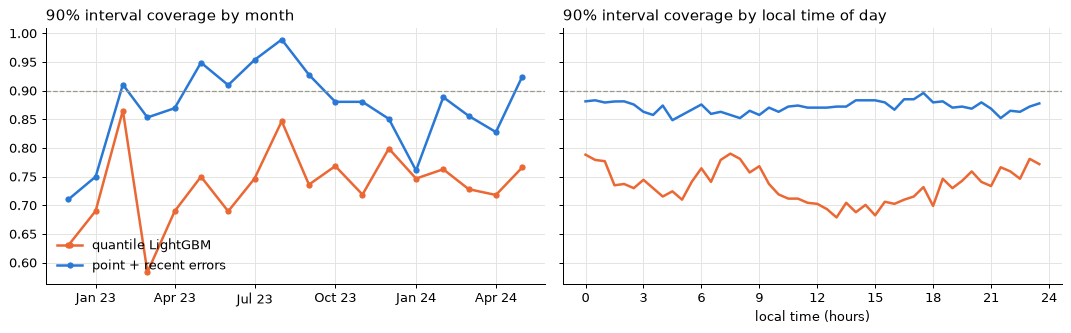

In [7]:
def covered(frame, low=0.05, high=0.95):
    return (frame["Demand_Outturn"] >= frame[f"q{low}"]) & (frame["Demand_Outturn"] <= frame[f"q{high}"])


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for frame, name, color in [(compare, "quantile LightGBM", ORANGE), (reference, "point + recent errors", BLUE)]:
    inside = covered(frame)
    by_month = inside.groupby(frame["fold"]).mean()
    axes[0].plot(pd.to_datetime(by_month.index), by_month.values, color=color, marker="o", markersize=4, label=name)
    by_time = inside.groupby(frame["slot"] / 2).mean()
    axes[1].plot(by_time.index, by_time.values, color=color, label=name)
for ax in axes:
    ax.axhline(0.9, color="#999990", linewidth=1, linestyle="--")
axes[0].set_title("90% interval coverage by month", loc="left")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[1].set_title("90% interval coverage by local time of day", loc="left")
axes[1].set_xticks(range(0, 25, 3))
axes[1].set_xlabel("local time (hours)")
axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()


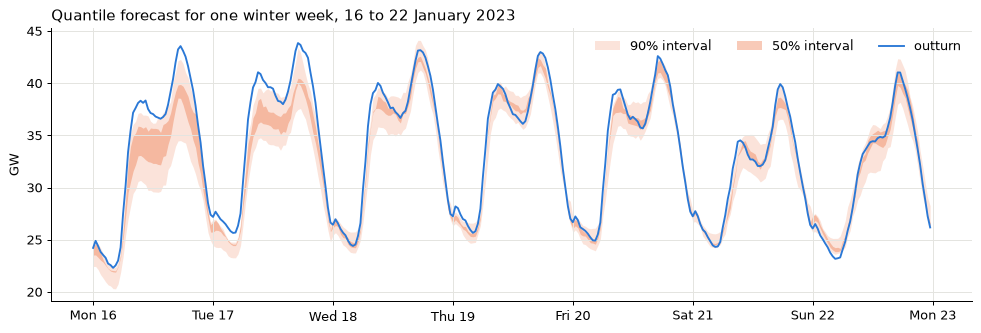

In [8]:
week = quantile[quantile["Date"].between("2023-01-16", "2023-01-22")]
hours = (week["start_utc"] - week["start_utc"].min()).dt.total_seconds() / 3600

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(hours, week["q0.05"] / 1000, week["q0.95"] / 1000, color=ORANGE, alpha=0.18, linewidth=0, label="90% interval")
ax.fill_between(hours, week["q0.25"] / 1000, week["q0.75"] / 1000, color=ORANGE, alpha=0.35, linewidth=0, label="50% interval")
ax.plot(hours, week["Demand_Outturn"] / 1000, color=BLUE, linewidth=1.5, label="outturn")
ax.set_xticks(range(0, 169, 24))
ax.set_xticklabels(pd.date_range("2023-01-16", periods=8).strftime("%a %d"))
ax.set_ylabel("GW")
ax.set_title("Quantile forecast for one winter week, 16 to 22 January 2023", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper right")
fig.tight_layout()
plt.show()


**Found:**

- **By month,** the quantile models stay below 90% in every month, between 58% and 86%. The
  reference is close to 90% in most months, but falls to 71% to 76% in December 2022, January 2023
  and January 2024: winter months whose errors were larger than those of the six months before.
- **By time of day,** the quantile models are worst around midday (68% to 72%), where notebook 06
  found the errors largest. The reference stays between 85% and 90% all day, because it takes its
  spread separately for each half-hour.
- **The example week** shows both sides: from Wednesday to Sunday the bands are narrow and the
  outturn sits inside them, while on Monday 16 January, after a weekend, demand ran above even the
  90% band all morning.


## Step 7. Coverage with forecast weather

**What:** rerun the quantile models for March to May 2024 with day-ahead weather forecasts, as in
notebook 06, and compare coverage with the actual-weather run on the same half-hours.

**Why:** the models learnt their spread from actual weather, where the weather inputs are exact.
With forecast weather there is an extra source of error the models never saw, so the intervals
may be too narrow. This is what the calibration in notebook 08 has to fix.


In [9]:
spring = FOLDS[FOLDS["fold"].isin(["2024-03", "2024-04", "2024-05"])]
spring_forecast = run_quantile_folds(features_forecast, train_table=features_actual, folds=spring)
spring_forecast[QCOLS] = np.sort(spring_forecast[QCOLS].to_numpy(), axis=1)
covered_days = features_forecast.groupby("Date")["shortwave_radiation"].apply(lambda s: s.notna().all())
spring_forecast = spring_forecast[spring_forecast["Date"].map(covered_days).fillna(False).astype(bool)]
spring_actual = quantile[quantile["start_utc"].isin(spring_forecast["start_utc"])]

pd.DataFrame({
    "actual weather": [pinball_table(spring_actual).mean(), *interval_table(spring_actual)["coverage"]],
    "forecast weather": [pinball_table(spring_forecast).mean(), *interval_table(spring_forecast)["coverage"]],
}, index=["mean pinball loss (MW)", "50% coverage", "80% coverage", "90% coverage"]).round(3)


,actual weather,forecast weather
mean pinball loss (MW),262.696,281.300
50% coverage,0.283,0.288
80% coverage,0.558,0.550
90% coverage,0.726,0.717


**Found:** with forecast weather, coverage barely changes (72% against 73% for the 90% interval),
but the pinball loss rises from 263 to 281 MW. So the forecast weather mostly shifts the quantiles
away from the outcome rather than making the models more overconfident. Both runs are too narrow by
about the same amount, which calibration has to correct either way.


## Step 8. Save the validation quantiles

Notebook 08 calibrates these intervals and then runs the final test.


In [10]:
quantile.to_parquet(PROCESSED / "validation_quantiles.parquet", index=False)
spring_forecast.to_parquet(PROCESSED / "spring2024_quantiles_forecast_weather.parquet", index=False)
print(len(quantile), len(spring_forecast))


35038 4078


## Summary and next step

| Method (validation, Dec 2022 to May 2024) | Mean pinball loss | 50% / 80% / 90% coverage |
|---|---|---|
| Quantile LightGBM, sorted | 266 MW | 29% / 57% / 74% |
| Point forecast + recent errors by half-hour | 243 MW | 48% / 77% / 87% |

**What I learnt**
- Separate quantile models give the right centre but far too narrow intervals, and their quantiles
  cross often.
- A simple method built on recent out-of-sample errors is better calibrated and scores better.
  Out-of-sample errors are the right yardstick for uncertainty; in-sample fits are not.

**Next (notebook 08):** conformal calibration of the quantile models, a comparison with the reference
on one proper score, and the single run on the test window against NESO.
